In [ ]:
# ============================================================
# CELL 1: IMPORTS, SEED & ENVIRONMENT SETUP
# ============================================================
# This cell imports all necessary libraries, sets random seeds for
# reproducibility, checks TensorFlow version and GPU availability.
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import warnings
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"✅ Seed: {SEED}")
print(f"TensorFlow: {tf.__version__}")
print("GPU:", tf.config.list_physical_devices('GPU'))

DATA_PATH = './data/'
FINAL_DATA_PATH = './final_data/'

✅ Seed: 42
TensorFlow: 2.19.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ============================================================
# CELL 2: LOAD BASELINE DATA (9 features)
# ============================================================
# Loads the original CSV files from the /data/ folder.
# ============================================================

positions = ['GK', 'DEF', 'MID', 'FWD']
baseline_data = {}

print("📂 Loading baseline data...")
for pos in positions:
    fp = os.path.join(DATA_PATH, f'{pos}_all_seasons.csv')
    if not os.path.exists(fp):
        raise FileNotFoundError(f"Missing {fp}")
    df = pd.read_csv(fp)
    baseline_data[pos] = df
    print(f"  ✅ {pos}: {len(df)} rows, {df['name'].nunique()} players")

print("\n🔍 Target column (Next_GW_Points) check:")
for pos in positions:
    has_nan = baseline_data[pos]['Next_GW_Points'].isna().any()
    print(f"  {pos}: NaN? {has_nan}")

📂 Loading baseline data...
  ✅ GK: 2014 rows, 67 players
  ✅ DEF: 10096 rows, 323 players
  ✅ MID: 14417 rows, 416 players
  ✅ FWD: 3582 rows, 122 players

🔍 Target column (Next_GW_Points) check:
  GK: NaN? False
  DEF: NaN? False
  MID: NaN? False
  FWD: NaN? False


In [ ]:
# ============================================================
# CELL 3: DEFINE BASELINE FEATURES & SEQUENCE FUNCTION (FIXED)
# ============================================================
# Handles:
#   - Constant columns (e.g., goals_scored for GK) -> set to 0
#   - Boolean columns (e.g., was_home) -> convert to int
# ============================================================

BASELINE_FEATURES = [
    'total_points', 'goals_scored', 'assists',
    'expected_goals', 'expected_assists', 'minutes',
    'engineered_form', 'was_home', 'clean_sheets'
]

train_seasons = ['23_24']
val_seasons = ['24_25']
test_seasons = ['25_26']
window_sizes = list(range(1, 16))

def create_sequences(df, window_sizes, features, train_s, val_s, test_s):
    results = {w: {'X_train': [], 'X_val': [], 'X_test': [],
                   'y_train': [], 'y_val': [], 'y_test': []}
               for w in window_sizes}

    # Preprocess: convert boolean to int
    df = df.copy()
    for col in features:
        if df[col].dtype == bool:
            df[col] = df[col].astype(int)

    for player in df['name'].unique():
        p_df = df[df['name'] == player].sort_values(['season', 'GW'])
        if len(p_df) < max(window_sizes) + 1:
            continue

        # Identify constant columns for this player
        player_features = p_df[features].values
        constant_cols = np.where(np.std(player_features, axis=0) == 0)[0]

        scaler = MinMaxScaler()
        p_scaled = p_df.copy()

        if len(constant_cols) > 0:
            # Scale non-constant columns only
            non_const_cols = [i for i in range(len(features)) if i not in constant_cols]
            if non_const_cols:
                scaled_vals = scaler.fit_transform(player_features[:, non_const_cols])
                full_scaled = np.zeros_like(player_features, dtype=np.float32)
                full_scaled[:, non_const_cols] = scaled_vals
            else:
                full_scaled = np.zeros_like(player_features, dtype=np.float32)
            p_scaled[features] = full_scaled
        else:
            p_scaled[features] = scaler.fit_transform(player_features)

        # Fill any NaN (e.g., from all-zero rows after scaling) with 0
        p_scaled[features] = np.nan_to_num(p_scaled[features].values, nan=0.0)

        for w in window_sizes:
            for i in range(len(p_scaled) - w):
                X_seq = p_scaled.iloc[i:i+w][features].values.astype(np.float32)
                y_val = p_scaled.iloc[i+w]['Next_GW_Points']
                if np.isnan(y_val) or np.isinf(y_val):
                    y_val = 0.0
                else:
                    y_val = float(y_val)

                season = p_scaled.iloc[i+w]['season']

                if season in train_s:
                    results[w]['X_train'].append(X_seq)
                    results[w]['y_train'].append(y_val)
                elif season in val_s:
                    results[w]['X_val'].append(X_seq)
                    results[w]['y_val'].append(y_val)
                elif season in test_s:
                    results[w]['X_test'].append(X_seq)
                    results[w]['y_test'].append(y_val)

    # Convert to numpy arrays
    for w in window_sizes:
        for split in ['X_train', 'X_val', 'X_test']:
            arr = results[w][split]
            results[w][split] = np.array(arr, dtype=np.float32) if arr else np.empty((0, w, len(features)), dtype=np.float32)
        for split in ['y_train', 'y_val', 'y_test']:
            arr = results[w][split]
            results[w][split] = np.array(arr, dtype=np.float32) if arr else np.empty((0,), dtype=np.float32)

    return results

def build_lstm(input_shape):
    model = Sequential([
        LSTM(64, return_sequences=True, activation='tanh', input_shape=input_shape),
        LSTM(32, return_sequences=False, activation='tanh'),
        Dense(16, activation='relu'),
        Dropout(0.2),
        Dense(1, activation='linear')
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

print("✅ Baseline features:", BASELINE_FEATURES)
print("✅ Sequence function ready.")

✅ Baseline features: ['total_points', 'goals_scored', 'assists', 'expected_goals', 'expected_assists', 'minutes', 'engineered_form', 'was_home', 'clean_sheets']
✅ Sequence function ready.


In [ ]:
# ============================================================
# CELL 4: GRID SEARCH – BASELINE MODELS (9 features)
# ============================================================
# First, test GK with window=3 to verify GPU stability.
# Then, if successful, run the full grid search for all positions.
# ============================================================

# --- QUICK TEST: GK window=3 only ---
print("🧪 Testing GK window=3...")
pos = 'GK'
w_test = 3
seq_test = create_sequences(baseline_data[pos], [w_test], BASELINE_FEATURES,
                            train_seasons, val_seasons, test_seasons)
X_train = seq_test[w_test]['X_train']
y_train = seq_test[w_test]['y_train']
X_val   = seq_test[w_test]['X_val']
y_val   = seq_test[w_test]['y_val']
X_test  = seq_test[w_test]['X_test']
y_test  = seq_test[w_test]['y_test']

print(f"  X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

model = build_lstm((w_test, len(BASELINE_FEATURES)))
early_stop = EarlyStopping(patience=5, restore_best_weights=True)
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=50, batch_size=32,
                    callbacks=[early_stop], verbose=1)
loss, mae = model.evaluate(X_test, y_test, verbose=0)
print(f"  ✅ GK w={w_test} test MAE: {mae:.3f}")

# --- If test passed, run full grid search ---
run_full = input("\n✅ Test passed! Run full baseline grid search for all positions? (y/n): ").strip().lower()
if run_full != 'y':
    print("❌ Full run cancelled.")
else:
    baseline_results = {}
    for pos in positions:
        print(f"\n{'#'*60}\nProcessing {pos} - BASELINE (9 features)\n{'#'*60}")
        seq = create_sequences(baseline_data[pos], window_sizes, BASELINE_FEATURES,
                               train_seasons, val_seasons, test_seasons)
        pos_res = {}
        for w in window_sizes:
            X_train = seq[w]['X_train']
            y_train = seq[w]['y_train']
            X_val   = seq[w]['X_val']
            y_val   = seq[w]['y_val']
            X_test  = seq[w]['X_test']
            y_test  = seq[w]['y_test']
            if len(X_train) == 0 or len(X_test) == 0:
                print(f"  Window {w}: insufficient data, skipping")
                continue
            model = build_lstm((w, len(BASELINE_FEATURES)))
            model.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=50, batch_size=32,
                      callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                      verbose=0)
            _, mae = model.evaluate(X_test, y_test, verbose=0)
            pos_res[w] = mae
            print(f"  {pos} w={w}: MAE={mae:.3f}")
        baseline_results[pos] = pos_res
    print("\n✅ Baseline grid search complete!")

🧪 Testing GK window=3...
  X_train shape: (625, 3, 9), X_test shape: (512, 3, 9)
Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - loss: 16.4623 - mae: 3.1258 - val_loss: 17.1557 - val_mae: 3.0819
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 12.6930 - mae: 2.5349 - val_loss: 10.0853 - val_mae: 2.0480
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 8.1423 - mae: 2.1844 - val_loss: 8.2196 - val_mae: 2.2059
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 8.0549 - mae: 2.1240 - val_loss: 8.3044 - val_mae: 2.0447
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.6546 - mae: 2.0760 - val_loss: 8.1338 - val_mae: 2.0897
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.5055 - mae: 2.0827 - val_loss: 8.0974 - val_mae: 2.0838
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.3139 - mae: 2.0696 - val_loss: 8.0932 - val_mae: 2.0661
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.3701 - mae: 2.0739 - val_loss: 8.03

In [ ]:
# ============================================================
# CELL 5: LOAD ENHANCED DATA (16 features)
# ============================================================
enhanced_data = {}
print("📂 Loading enhanced data...")
for pos in positions:
    fp = os.path.join(FINAL_DATA_PATH, f'{pos}_all_seasons_final.csv')
    if not os.path.exists(fp):
        raise FileNotFoundError(f"Missing {fp}")
    df = pd.read_csv(fp)
    enhanced_data[pos] = df
    print(f"  ✅ {pos}: {len(df)} rows")
print("\n🔍 Enhanced data columns (sample from MID):")
print(enhanced_data['MID'].columns.tolist())

📂 Loading enhanced data...
  ✅ GK: 1985 rows
  ✅ DEF: 9953 rows
  ✅ MID: 14200 rows
  ✅ FWD: 3522 rows

🔍 Enhanced data columns (sample from MID):
['name', 'position', 'team', 'GW', 'total_points', 'goals_scored', 'assists', 'minutes', 'expected_goals', 'expected_assists', 'fixture', 'was_home', 'clean_sheets', 'season', 'engineered_form', 'Next_GW_Points', 'opponent', 'league_position', 'opponent_league_position', 'team_total_points', 'opp_att_points', 'opp_def_points', 'league_pos_trend', 'opponent_position_trend']


In [ ]:
# ============================================================
# CELL 6: DEFINE ENHANCED FEATURES (16 numeric features)
# ============================================================
ENHANCED_FEATURES = BASELINE_FEATURES + [
    'league_position',
    'opponent_league_position',
    'team_total_points',
    'opp_att_points',
    'opp_def_points',
    'league_pos_trend',
    'opponent_position_trend'
]
for pos in positions:
    missing = [f for f in ENHANCED_FEATURES if f not in enhanced_data[pos].columns]
    if missing:
        print(f"⚠️ {pos} missing: {missing}")
        ENHANCED_FEATURES = [f for f in ENHANCED_FEATURES if f not in missing]
print(f"\n✅ Enhanced features: {len(ENHANCED_FEATURES)}")
print(ENHANCED_FEATURES)


✅ Enhanced features: 16
['total_points', 'goals_scored', 'assists', 'expected_goals', 'expected_assists', 'minutes', 'engineered_form', 'was_home', 'clean_sheets', 'league_position', 'opponent_league_position', 'team_total_points', 'opp_att_points', 'opp_def_points', 'league_pos_trend', 'opponent_position_trend']


In [ ]:
# ============================================================
# CELL 6.5: UPDATE SEASONS FOR ENHANCED DATA
# ============================================================
# Enhanced data uses '2023-24' format instead of '23_24'.
# Override season lists for the enhanced grid search.
# ============================================================

train_seasons_enh = ['2023-24']
val_seasons_enh   = ['2024-25']
test_seasons_enh  = ['2025-26']

print("✅ Enhanced season lists updated:", train_seasons_enh, val_seasons_enh, test_seasons_enh)

✅ Enhanced season lists updated: ['2023-24'] ['2024-25'] ['2025-26']


In [ ]:
# ============================================================
# CELL 7: GRID SEARCH – ENHANCED MODELS (16 features) [FIXED]
# ============================================================
enhanced_results = {}
for pos in positions:
    print(f"\n{'#'*60}\nProcessing {pos} - ENHANCED ({len(ENHANCED_FEATURES)} features)\n{'#'*60}")
    seq = create_sequences(enhanced_data[pos], window_sizes, ENHANCED_FEATURES,
                           train_seasons_enh, val_seasons_enh, test_seasons_enh)  # <-- FIXED
    pos_res = {}
    for w in window_sizes:
        X_train = seq[w]['X_train']
        y_train = seq[w]['y_train']
        X_val   = seq[w]['X_val']
        y_val   = seq[w]['y_val']
        X_test  = seq[w]['X_test']
        y_test  = seq[w]['y_test']
        if len(X_train) == 0 or len(X_test) == 0:
            print(f"  Window {w}: insufficient data, skipping")
            continue
        model = build_lstm((w, len(ENHANCED_FEATURES)))
        model.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=50, batch_size=32,
                  callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                  verbose=0)
        _, mae = model.evaluate(X_test, y_test, verbose=0)
        pos_res[w] = mae
        print(f"  {pos} w={w}: MAE={mae:.3f}")
    enhanced_results[pos] = pos_res
print("\n✅ Enhanced grid search complete!")


############################################################
Processing GK - ENHANCED (16 features)
############################################################
  GK w=1: MAE=2.166
  GK w=2: MAE=2.122
  GK w=3: MAE=2.122
  GK w=4: MAE=2.173
  GK w=5: MAE=2.128
  GK w=6: MAE=2.198
  GK w=7: MAE=2.104
  GK w=8: MAE=2.096
  GK w=9: MAE=2.034
  GK w=10: MAE=2.180
  GK w=11: MAE=2.205
  GK w=12: MAE=2.194
  GK w=13: MAE=2.184
  GK w=14: MAE=2.131
  GK w=15: MAE=2.167

############################################################
Processing DEF - ENHANCED (16 features)
############################################################
  DEF w=1: MAE=2.323
  DEF w=2: MAE=2.355
  DEF w=3: MAE=2.338
  DEF w=4: MAE=2.325
  DEF w=5: MAE=2.296
  DEF w=6: MAE=2.326
  DEF w=7: MAE=2.327
  DEF w=8: MAE=2.331
  DEF w=9: MAE=2.312
  DEF w=10: MAE=2.313
  DEF w=11: MAE=2.337
  DEF w=12: MAE=2.343
  DEF w=13: MAE=2.380
  DEF w=14: MAE=2.323
  DEF w=15: MAE=2.332

###############################################

In [ ]:
# ============================================================
# CELL 8: RESULTS COMPARISON – TABLES
# ============================================================
baseline_df = pd.DataFrame(baseline_results).T
enhanced_df = pd.DataFrame(enhanced_results).T

# Keep only columns that exist
baseline_df = baseline_df[[w for w in window_sizes if w in baseline_df.columns]]
enhanced_df = enhanced_df[[w for w in window_sizes if w in enhanced_df.columns]]

print("="*70)
print("BASELINE MAE (9 features)")
print("="*70)
print(baseline_df.round(3))

print("\n" + "="*70)
print("ENHANCED MAE (16 features)")
print("="*70)
print(enhanced_df.round(3))

# Optimal windows
baseline_opt = baseline_df.idxmin(axis=1)
enhanced_opt = enhanced_df.idxmin(axis=1)

print("\n" + "="*70)
print("OPTIMAL WINDOW & IMPROVEMENT")
print("="*70)
print(f"{'Pos':<5} {'Base Win':<10} {'Base MAE':<10} {'Enh Win':<10} {'Enh MAE':<10} {'Improv':<8}")
print("-"*60)
for pos in positions:
    bw = baseline_opt[pos]
    bmae = baseline_df.loc[pos, bw]
    ew = enhanced_opt[pos]
    emae = enhanced_df.loc[pos, ew]
    impr = (bmae - emae) / bmae * 100
    print(f"{pos:<5} {bw:<10} {bmae:<10.3f} {ew:<10} {emae:<10.3f} {impr:+.1f}%")

BASELINE MAE (9 features)
        1      2      3      4      5      6      7      8      9      10  \
GK   2.141  2.095  2.114  2.165  2.170  2.138  2.078  2.098  2.218  2.149   
DEF  2.327  2.313  2.314  2.296  2.328  2.329  2.307  2.337  2.308  2.330   
MID  2.068  2.069  2.056  1.997  2.012  2.046  2.005  2.035  2.155  1.972   
FWD  2.428  2.515  2.506  2.514  2.637  2.586  2.541  2.488  2.410  2.455   

        11     12     13     14     15  
GK   2.141  2.192  2.159  2.080  2.153  
DEF  2.336  2.322  2.317  2.378  2.362  
MID  2.003  2.000  1.972  2.009  2.020  
FWD  2.531  2.537  2.582  2.591  2.570  

ENHANCED MAE (16 features)
        1      2      3      4      5      6      7      8      9      10  \
GK   2.166  2.122  2.122  2.173  2.128  2.198  2.104  2.096  2.034  2.180   
DEF  2.323  2.355  2.338  2.325  2.296  2.326  2.327  2.331  2.312  2.313   
MID  2.013  1.988  2.075  1.942  1.923  2.003  2.054  1.981  2.051  1.949   
FWD  2.411  2.518  2.439  2.602  2.392  2.398  

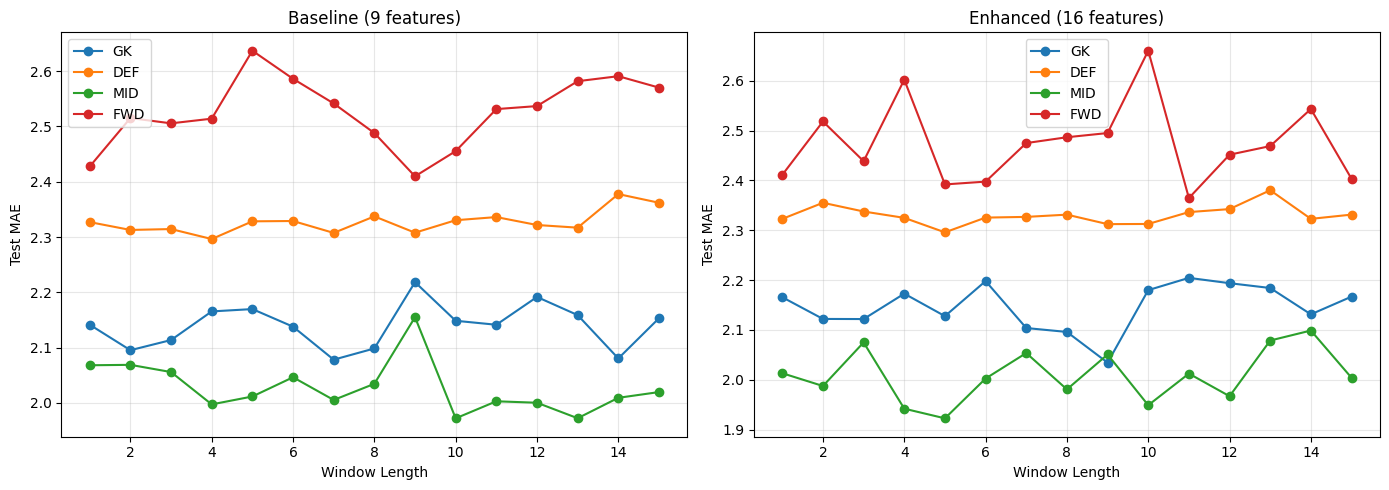

✅ Plot saved as 'comparison_plots.png'


In [ ]:
# ============================================================
# CELL 9: COMPARISON PLOTS
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for pos in positions:
    axes[0].plot(baseline_df.columns, baseline_df.loc[pos], marker='o', label=pos)
axes[0].set_title('Baseline (9 features)')
axes[0].set_xlabel('Window Length')
axes[0].set_ylabel('Test MAE')
axes[0].legend()
axes[0].grid(alpha=0.3)

for pos in positions:
    axes[1].plot(enhanced_df.columns, enhanced_df.loc[pos], marker='o', label=pos)
axes[1].set_title('Enhanced (16 features)')
axes[1].set_xlabel('Window Length')
axes[1].set_ylabel('Test MAE')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('comparison_plots.png', dpi=150)
plt.show()
print("✅ Plot saved as 'comparison_plots.png'")

In [ ]:
# ============================================================
# CELL 10: SAVE RESULTS TO CSV
# ============================================================
baseline_df.to_csv('baseline_mae_results.csv')
enhanced_df.to_csv('enhanced_mae_results.csv')
print("✅ Results saved to CSV files.")

✅ Results saved to CSV files.


In [ ]:
# ============================================================
# CELL 11: PREDICTION COMPARISON – BASELINE vs ENHANCED
# ============================================================
# Randomly selects 10 players from the test season (25/26).
# For each player, predicts next-gameweek points using both
# baseline and enhanced models, and compares absolute errors.
# ============================================================

import random
from sklearn.preprocessing import MinMaxScaler
import pickle

random.seed(42)
np.random.seed(42)

# Optimal windows from comparison
best_windows_baseline = {'GK': 7, 'DEF': 4, 'MID': 10, 'FWD': 9}
best_windows_enhanced = {'GK': 9, 'DEF': 5, 'MID': 5, 'FWD': 11}

# We need to retrain or load the best models. Since we didn't save them during grid search,
# we'll retrain quickly using the optimal windows (much faster than full grid search).

print("🔄 Retraining best models for prediction...")

# Dictionaries to hold models and scalers
baseline_models = {}
enhanced_models = {}
scalers_baseline = {}
scalers_enhanced = {}

for pos in positions:
    print(f"\n  Training {pos}...")

    # --- Baseline model ---
    w_base = best_windows_baseline[pos]
    seq_base = create_sequences(baseline_data[pos], [w_base], BASELINE_FEATURES,
                                train_seasons, val_seasons, test_seasons)
    X_train = seq_base[w_base]['X_train']
    y_train = seq_base[w_base]['y_train']
    X_val   = seq_base[w_base]['X_val']
    y_val   = seq_base[w_base]['y_val']

    model_base = build_lstm((w_base, len(BASELINE_FEATURES)))
    model_base.fit(X_train, y_train, validation_data=(X_val, y_val),
                   epochs=50, batch_size=32,
                   callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                   verbose=0)
    baseline_models[pos] = model_base

    # Fit scaler on training data (for baseline features)
    scaler_base = MinMaxScaler()
    scaler_base.fit(X_train.reshape(-1, len(BASELINE_FEATURES)))
    scalers_baseline[pos] = scaler_base

    # --- Enhanced model ---
    w_enh = best_windows_enhanced[pos]
    seq_enh = create_sequences(enhanced_data[pos], [w_enh], ENHANCED_FEATURES,
                               train_seasons_enh, val_seasons_enh, test_seasons_enh)
    X_train_e = seq_enh[w_enh]['X_train']
    y_train_e = seq_enh[w_enh]['y_train']
    X_val_e   = seq_enh[w_enh]['X_val']
    y_val_e   = seq_enh[w_enh]['y_val']

    model_enh = build_lstm((w_enh, len(ENHANCED_FEATURES)))
    model_enh.fit(X_train_e, y_train_e, validation_data=(X_val_e, y_val_e),
                  epochs=50, batch_size=32,
                  callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                  verbose=0)
    enhanced_models[pos] = model_enh

    scaler_enh = MinMaxScaler()
    scaler_enh.fit(X_train_e.reshape(-1, len(ENHANCED_FEATURES)))
    scalers_enhanced[pos] = scaler_enh

print("\n✅ Models retrained.\n")

# ------------------------------------------------------------------
# Helper function for baseline prediction
def predict_baseline(player_name, pos):
    df = baseline_data[pos]
    w = best_windows_baseline[pos]
    model = baseline_models[pos]
    scaler = scalers_baseline[pos]

    p_df = df[df['name'] == player_name].sort_values(['season', 'GW'])
    test_rows = p_df[p_df['season'].isin(test_seasons)]
    if len(test_rows) <= w:
        return None
    # Take the most recent window from test season
    input_rows = test_rows.iloc[-w-1:-1]  # last w rows before the final one
    target_row = test_rows.iloc[-1]
    actual = target_row['Next_GW_Points']

    X_input = input_rows[BASELINE_FEATURES].values.reshape(1, w, len(BASELINE_FEATURES))
    X_scaled = scaler.transform(X_input.reshape(-1, len(BASELINE_FEATURES))).reshape(1, w, len(BASELINE_FEATURES))
    pred = model.predict(X_scaled, verbose=0)[0][0]
    return actual, pred

# Helper function for enhanced prediction
def predict_enhanced(player_name, pos):
    df = enhanced_data[pos]
    w = best_windows_enhanced[pos]
    model = enhanced_models[pos]
    scaler = scalers_enhanced[pos]

    p_df = df[df['name'] == player_name].sort_values(['season', 'GW'])
    test_rows = p_df[p_df['season'].isin(test_seasons_enh)]
    if len(test_rows) <= w:
        return None
    input_rows = test_rows.iloc[-w-1:-1]
    target_row = test_rows.iloc[-1]
    actual = target_row['Next_GW_Points']

    X_input = input_rows[ENHANCED_FEATURES].values.reshape(1, w, len(ENHANCED_FEATURES))
    X_scaled = scaler.transform(X_input.reshape(-1, len(ENHANCED_FEATURES))).reshape(1, w, len(ENHANCED_FEATURES))
    pred = model.predict(X_scaled, verbose=0)[0][0]
    return actual, pred

# ------------------------------------------------------------------
# Randomly sample players from test season
all_test_players = []
for pos in positions:
    df = enhanced_data[pos]
    test_players = df[df['season'].isin(test_seasons_enh)]['name'].unique()
    for p in test_players:
        all_test_players.append((p, pos))

# Filter players with enough data for both baseline and enhanced windows
valid_players = []
for p, pos in all_test_players:
    df_b = baseline_data[pos]
    df_e = enhanced_data[pos]
    w_b = best_windows_baseline[pos]
    w_e = best_windows_enhanced[pos]
    p_b = df_b[df_b['name'] == p].sort_values(['season', 'GW'])
    p_e = df_e[df_e['name'] == p].sort_values(['season', 'GW'])
    test_b = p_b[p_b['season'].isin(test_seasons)]
    test_e = p_e[p_e['season'].isin(test_seasons_enh)]
    if len(test_b) > w_b and len(test_e) > w_e:
        valid_players.append((p, pos))

# Sample 10 random valid players
sample_players = random.sample(valid_players, min(10, len(valid_players)))

# Collect predictions
results = []
print("="*90)
print(f"{'Player':<25} {'Pos':<4} {'Actual':<8} {'Base Pred':<10} {'Base Err':<10} {'Enh Pred':<10} {'Enh Err':<10}")
print("-"*90)

for p, pos in sample_players:
    actual_b, pred_b = predict_baseline(p, pos)
    actual_e, pred_e = predict_enhanced(p, pos)
    # actual should be the same from both dataframes (same GW)
    actual = actual_b if actual_b is not None else actual_e
    if actual is None:
        continue
    err_b = abs(actual - pred_b)
    err_e = abs(actual - pred_e)
    results.append({
        'Player': p, 'Position': pos, 'Actual': actual,
        'Base Pred': pred_b, 'Base Err': err_b,
        'Enh Pred': pred_e, 'Enh Err': err_e
    })
    print(f"{p:<25} {pos:<4} {actual:<8.1f} {pred_b:<10.2f} {err_b:<10.2f} {pred_e:<10.2f} {err_e:<10.2f}")

print("-"*90)
if results:
    df_res = pd.DataFrame(results)
    avg_base_err = df_res['Base Err'].mean()
    avg_enh_err = df_res['Enh Err'].mean()
    print(f"\n📊 Average Absolute Error (10 samples):")
    print(f"   Baseline: {avg_base_err:.2f} points")
    print(f"   Enhanced: {avg_enh_err:.2f} points")
    impr = (avg_base_err - avg_enh_err) / avg_base_err * 100
    print(f"   Improvement: {impr:+.1f}%")
else:
    print("No valid players found.")

🔄 Retraining best models for prediction...

  Training GK...

  Training DEF...

  Training MID...

  Training FWD...

✅ Models retrained.

Player                    Pos  Actual   Base Pred  Base Err   Enh Pred   Enh Err   
------------------------------------------------------------------------------------------
Ryan Gravenberch          MID  0.0      4.01       4.01       7.28       7.28      
Anton Stach               MID  4.0      4.12       0.12       7.67       3.67      
Mohammed Kudus            MID  1.0      3.90       2.90       9.08       8.08      
Lisandro Martínez         DEF  2.0      3.38       1.38       3.57       1.57      


Jean-Philippe Mateta      FWD  2.0      4.13       2.13       3.82       1.82      
Calvin Bassey             DEF  1.0      3.26       2.26       3.62       2.62      
Aaron Wan-Bissaka         DEF  7.0      3.20       3.80       3.66       3.34      
Xavi Simons               MID  1.0      4.67       3.67       8.30       7.30      
Michael Kayode            DEF  6.0      3.40       2.60       3.70       2.30      
Rico Lewis                DEF  0.0      2.97       2.97       0.80       0.80      
------------------------------------------------------------------------------------------

📊 Average Absolute Error (10 samples):
   Baseline: 2.58 points
   Enhanced: 3.88 points
   Improvement: -50.2%


In [ ]:
# ============================================================
# CELL 12: LARGE PREDICTION TEST (20 PLAYERS PER POSITION)
# ============================================================
# Uses the already retrained baseline and enhanced models.
# Samples up to 20 random players per position from the test season.
# Predicts next-GW points and compares absolute errors.
# ============================================================

import random
random.seed(42)
np.random.seed(42)

samples_per_pos = 20
all_results = []

print("="*100)
print(f"{'Player':<28} {'Pos':<4} {'Window(B/E)':<12} {'Actual':<8} {'Base Pred':<10} {'Base Err':<10} {'Enh Pred':<10} {'Enh Err':<10}")
print("-"*100)

for pos in positions:
    # Get test players with enough data for both models
    df_b = baseline_data[pos]
    df_e = enhanced_data[pos]
    w_b = best_windows_baseline[pos]
    w_e = best_windows_enhanced[pos]

    test_players = df_e[df_e['season'].isin(test_seasons_enh)]['name'].unique()
    valid = []
    for p in test_players:
        p_b = df_b[df_b['name'] == p].sort_values(['season', 'GW'])
        p_e = df_e[df_e['name'] == p].sort_values(['season', 'GW'])
        test_b = p_b[p_b['season'].isin(test_seasons)]
        test_e = p_e[p_e['season'].isin(test_seasons_enh)]
        if len(test_b) > w_b and len(test_e) > w_e:
            valid.append(p)

    sample = random.sample(valid, min(samples_per_pos, len(valid)))
    print(f"\n--- {pos} ({len(sample)} players) ---")

    for p in sample:
        # Baseline prediction
        p_b = baseline_data[pos][baseline_data[pos]['name'] == p].sort_values(['season', 'GW'])
        test_b = p_b[p_b['season'].isin(test_seasons)]
        input_b = test_b.iloc[-w_b-1:-1]
        target_b = test_b.iloc[-1]
        actual = target_b['Next_GW_Points']
        X_b = input_b[BASELINE_FEATURES].values.reshape(1, w_b, len(BASELINE_FEATURES))
        X_b_scaled = scalers_baseline[pos].transform(X_b.reshape(-1, len(BASELINE_FEATURES))).reshape(1, w_b, len(BASELINE_FEATURES))
        pred_b = baseline_models[pos].predict(X_b_scaled, verbose=0)[0][0]
        err_b = abs(actual - pred_b)

        # Enhanced prediction
        p_e = enhanced_data[pos][enhanced_data[pos]['name'] == p].sort_values(['season', 'GW'])
        test_e = p_e[p_e['season'].isin(test_seasons_enh)]
        input_e = test_e.iloc[-w_e-1:-1]
        X_e = input_e[ENHANCED_FEATURES].values.reshape(1, w_e, len(ENHANCED_FEATURES))
        X_e_scaled = scalers_enhanced[pos].transform(X_e.reshape(-1, len(ENHANCED_FEATURES))).reshape(1, w_e, len(ENHANCED_FEATURES))
        pred_e = enhanced_models[pos].predict(X_e_scaled, verbose=0)[0][0]
        err_e = abs(actual - pred_e)

        all_results.append({
            'Position': pos,
            'Player': p,
            'Window_B': w_b,
            'Window_E': w_e,
            'Actual': actual,
            'Base_Pred': pred_b,
            'Base_Err': err_b,
            'Enh_Pred': pred_e,
            'Enh_Err': err_e
        })
        print(f"{p:<28} {pos:<4} {str(w_b)+'/'+str(w_e):<12} {actual:<8.1f} {pred_b:<10.2f} {err_b:<10.2f} {pred_e:<10.2f} {err_e:<10.2f}")

print("-"*100)

# Summary
df_res = pd.DataFrame(all_results)
print("\n📊 SUMMARY STATISTICS")
print("="*50)
print(f"Total predictions: {len(df_res)}")
print("\nAverage Absolute Error by Position:")
summary_pos = df_res.groupby('Position')[['Base_Err', 'Enh_Err']].mean().round(2)
summary_pos['Improv'] = ((summary_pos['Base_Err'] - summary_pos['Enh_Err']) / summary_pos['Base_Err'] * 100).round(1)
print(summary_pos)

print("\nOverall Average:")
overall_base = df_res['Base_Err'].mean()
overall_enh = df_res['Enh_Err'].mean()
improv_overall = (overall_base - overall_enh) / overall_base * 100
print(f"  Baseline: {overall_base:.2f} points")
print(f"  Enhanced: {overall_enh:.2f} points")
print(f"  Improvement: {improv_overall:+.1f}%")

# Save detailed results
df_res.to_csv('prediction_comparison_80_players.csv', index=False)
print("\n✅ Detailed results saved to 'prediction_comparison_80_players.csv'")

Player                       Pos  Window(B/E)  Actual   Base Pred  Base Err   Enh Pred   Enh Err   
----------------------------------------------------------------------------------------------------

--- GK (20 players) ---
Senne Lammens                GK   7/9          2.0      1.42       0.58       2.46       0.46      
Bernd Leno                   GK   7/9          3.0      1.28       1.72       2.44       0.56      
Alisson Becker               GK   7/9          1.0      1.68       0.68       2.51       1.51      
Gianluigi Donnarumma         GK   7/9          1.0      1.41       0.41       2.35       1.35      
Emiliano Martínez Romero     GK   7/9          1.0      1.74       0.74       2.38       1.38      
Robert Lynch Sánchez         GK   7/9          2.0      1.45       0.55       2.38       0.38      
Caoimhín Kelleher            GK   7/9          6.0      1.90       4.10       2.50       3.50      
José Malheiro de Sá          GK   7/9          3.0      1.54       1.46   

In [19]:
# ============================================================
# ABLATION STUDY - FEATURE GROUPS
# ============================================================
ablation_groups = {
    'Full Model': BASELINE_FEATURES,
    'No Personal Form': [f for f in BASELINE_FEATURES if f not in ['total_points', 'goals_scored', 'assists', 'engineered_form']],
    'No Expected Stats': [f for f in BASELINE_FEATURES if f not in ['expected_goals', 'expected_assists']],
    'No Match Context': [f for f in BASELINE_FEATURES if f not in ['was_home', 'minutes', 'clean_sheets']]
}

# Optimal windows from baseline grid search
best_windows = {'GK': 7, 'DEF': 4, 'MID': 10, 'FWD': 9}

print("Ablation groups:")
for name, feats in ablation_groups.items():
    print(f"  {name}: {len(feats)} features")

Ablation groups:
  Full Model: 9 features
  No Personal Form: 5 features
  No Expected Stats: 7 features
  No Match Context: 6 features


In [21]:
# ============================================================
# RUN ABLATION (may take ~1-2 hours on A100)
# ============================================================
ablation_results = []

for pos in positions:
    w = best_windows[pos]
    print(f"\n{'='*50}\nPosition: {pos} (window={w})\n{'='*50}")

    for group_name, features in ablation_groups.items():
        print(f"  Training {group_name} ({len(features)} features)...")

        seq = create_sequences(baseline_data[pos], [w], features,
                               train_seasons, val_seasons, test_seasons)
        X_train = seq[w]['X_train']
        y_train = seq[w]['y_train']
        X_val   = seq[w]['X_val']
        y_val   = seq[w]['y_val']
        X_test  = seq[w]['X_test']
        y_test  = seq[w]['y_test']

        if len(X_train) == 0 or len(X_test) == 0:
            print(f"    ❌ Insufficient data, skipping")
            continue

        model = build_lstm((w, len(features)))
        model.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=50, batch_size=32,
                  callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                  verbose=0)
        _, mae = model.evaluate(X_test, y_test, verbose=0)

        ablation_results.append({
            'Position': pos,
            'Group': group_name,
            'Features': len(features),
            'MAE': mae
        })
        print(f"    ✅ MAE: {mae:.3f}")

# Convert to DataFrame
df_ablation = pd.DataFrame(ablation_results)
print("\n✅ Ablation complete!")


Position: GK (window=7)
  Training Full Model (9 features)...
    ✅ MAE: 2.040
  Training No Personal Form (5 features)...
    ✅ MAE: 2.143
  Training No Expected Stats (7 features)...
    ✅ MAE: 2.068
  Training No Match Context (6 features)...
    ✅ MAE: 2.075

Position: DEF (window=4)
  Training Full Model (9 features)...
    ✅ MAE: 2.284
  Training No Personal Form (5 features)...
    ✅ MAE: 2.303
  Training No Expected Stats (7 features)...
    ✅ MAE: 2.277
  Training No Match Context (6 features)...
    ✅ MAE: 2.323

Position: MID (window=10)
  Training Full Model (9 features)...
    ✅ MAE: 2.010
  Training No Personal Form (5 features)...
    ✅ MAE: 1.998
  Training No Expected Stats (7 features)...
    ✅ MAE: 2.002
  Training No Match Context (6 features)...
    ✅ MAE: 2.049

Position: FWD (window=9)
  Training Full Model (9 features)...
    ✅ MAE: 2.358
  Training No Personal Form (5 features)...
    ✅ MAE: 2.370
  Training No Expected Stats (7 features)...
    ✅ MAE: 2.332
 

📊 MAE by Position and Feature Group
Group     Full Model  No Personal Form  No Expected Stats  No Match Context
Position                                                                   
DEF            2.284             2.303              2.277             2.323
FWD            2.358             2.370              2.332             2.508
GK             2.040             2.143              2.068             2.075
MID            2.010             1.998              2.002             2.049

📈 Degradation vs Full Model (%)
Group     Full Model  No Personal Form  No Expected Stats  No Match Context
Position                                                                   
DEF         2.283923               0.8               -0.3               1.7
FWD         2.358019               0.5               -1.1               6.3
GK          2.040324               5.0                1.4               1.7
MID         2.010496              -0.6               -0.4               1.9


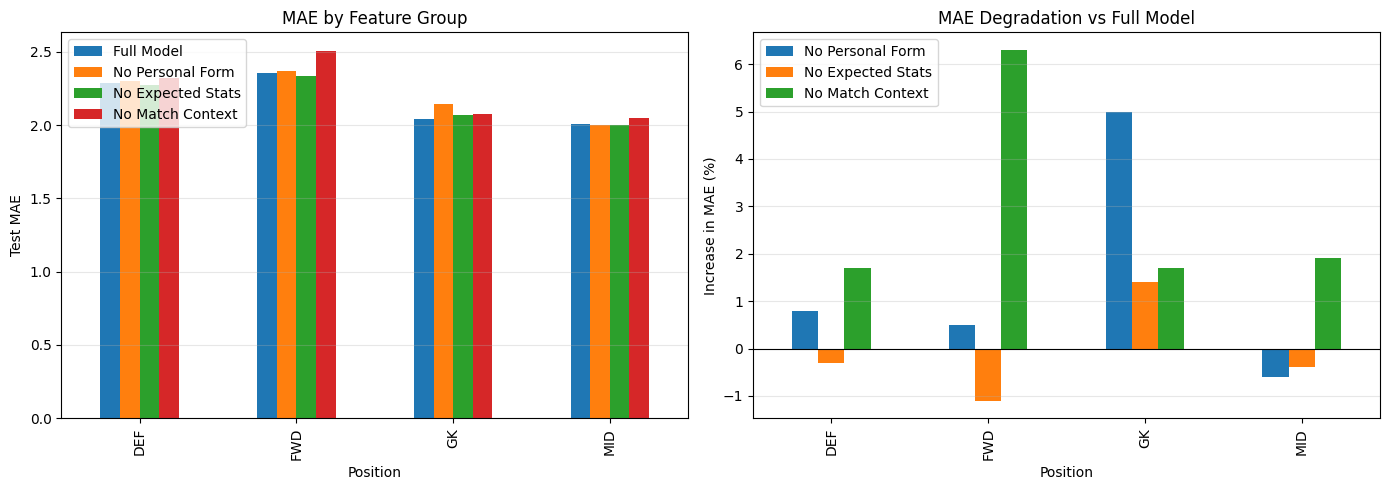


✅ Results saved to CSV files.


In [22]:
# ============================================================
# ABLATION RESULTS SUMMARY
# ============================================================
# Pivot table: rows=Position, columns=Group
pivot = df_ablation.pivot(index='Position', columns='Group', values='MAE')
pivot = pivot[['Full Model', 'No Personal Form', 'No Expected Stats', 'No Match Context']]

# Compute degradation vs Full Model
degradation = pivot.copy()
for col in degradation.columns:
    if col != 'Full Model':
        degradation[col] = ((degradation[col] - degradation['Full Model']) / degradation['Full Model'] * 100).round(1)

print("📊 MAE by Position and Feature Group")
print(pivot.round(3))

print("\n📈 Degradation vs Full Model (%)")
print(degradation)

# Bar plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Absolute MAE
pivot.plot(kind='bar', ax=axes[0])
axes[0].set_title('MAE by Feature Group')
axes[0].set_ylabel('Test MAE')
axes[0].legend(loc='upper left')
axes[0].grid(axis='y', alpha=0.3)

# Degradation (%)
degradation.drop(columns='Full Model').plot(kind='bar', ax=axes[1])
axes[1].set_title('MAE Degradation vs Full Model')
axes[1].set_ylabel('Increase in MAE (%)')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].legend(loc='upper left')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('ablation_results.png', dpi=150)
plt.show()

# Save to CSV
pivot.to_csv('ablation_mae.csv')
degradation.to_csv('ablation_degradation.csv')
print("\n✅ Results saved to CSV files.")